# Smart Beta and Factor Investing

**FINM 36700 Portfolio and Risk Management**

Case link: [Smart Beta and Factor Investing](https://markhendricks.github.io/finm-portfolio/case_studies/Smart%20Beta%20and%20Factor%20Investing.html)

Data: `data/factor_pricing_data.xlsx`: monthly excess returns on six factors (MKT, SMB, HML, RMW, CMA, UMD), January 1980 – April 2025.

# Section 2.1 - Factor Statistics

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

path = "data/factor_pricing_data.xlsx"
F = pd.read_excel(path, sheet_name="factors (excess returns)", index_col=0, parse_dates=True)

def perf_stats(df):
    out = pd.DataFrame({"Ann. Mean": df.mean() * 12, "Ann. Vol": df.std() * np.sqrt(12)})
    out["Ann. Sharpe"] = out["Ann. Mean"] / out["Ann. Vol"]
    out["t-stat (mean)"] = df.mean() / df.std() * np.sqrt(len(df))
    return out

def show(df):
    ratio = ("Sharpe", "t-stat")
    fmt = {c: "{:.2f}" if any(k in str(c) for k in ratio) else "{:.2%}" for c in df.columns}
    display(df.style.format(fmt))

print(f"{F.index[0]:%b %Y} - {F.index[-1]:%b %Y}: {len(F)} months, {F.isna().sum().sum()} missing values")
show(perf_stats(F))

Jan 1980 - Apr 2025: 544 months, 0 missing values


,Ann. Mean,Ann. Vol,Ann. Sharpe,t-stat (mean)
MKT,8.49%,15.64%,0.54,3.66
SMB,0.54%,10.14%,0.05,0.36
HML,2.65%,10.89%,0.24,1.64
RMW,4.51%,8.31%,0.54,3.66
CMA,2.77%,7.25%,0.38,2.57
UMD,6.18%,15.35%,0.40,2.71


MKT - market, SMB (Small Minus Big) - size, HML (High Minus Low) - value, RMW (Robust Minus Weak) - profitability, CMA (Conservative Minus Aggressive) - investment, UMD (Up Minus Down) - momentum

**Observations:** 
MKT and RMW have the highest Sharpe ratios (0.54 each), followed by UMD (0.40) and CMA (0.38). SMB is the weakest by far (0.05). UMD's vol (15.35%) is almost as high as the market's (15.64%), while RMW and CMA have the lowest vols (8.31% and 7.25%).

# Section 2.2 - Risk Premia and Performance Since 2015

In [3]:
pre, post = F.loc[:"2014"], F.loc["2015":]
periods = {"Jan 1980 - Dec 2014": pre, "Jan 2015 - Apr 2025": post}

show(pd.concat({k: perf_stats(v) for k, v in periods.items()}, axis=1))
show((1 + post).prod().sub(1).to_frame("Cum. return since 2015").T)

,MKT,SMB,HML,RMW,CMA,UMD
Cum. return since 2015,165.61%,-29.01%,-22.06%,54.32%,-15.54%,17.38%


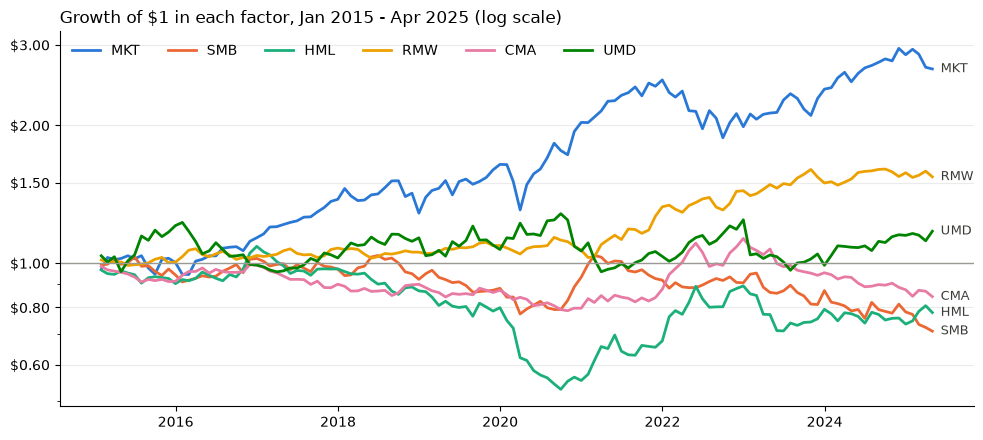

In [3]:
colors = dict(zip(F.columns, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
cum = (1 + post).cumprod()

fig, ax = plt.subplots(figsize=(10, 4.5))
for c in F.columns:
    ax.plot(cum.index, cum[c], color=colors[c], lw=2, label=c)
    ax.annotate(c, (cum.index[-1], cum[c].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color="#3b3b38")
ax.axhline(1, color="#9a9a94", lw=1)
ax.set_yscale("log")
ax.set_yticks([0.6, 0.8, 1, 1.5, 2, 3])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:.2f}"))
ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.set_title("Growth of $1 in each factor, Jan 2015 - Apr 2025 (log scale)", loc="left")
ax.legend(ncol=6, frameon=False, loc="upper left")
ax.grid(axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Does each factor have a positive risk premium?** Yes: all six sample means are positive. Some ar emore statistically clear than others though (t > 2): MKT (8.49%, t = 3.66), RMW (4.51%, t = 3.66), UMD (6.18%, t = 2.71), CMA (2.77%, t = 2.57). Others are not statistically significant: HML (2.65%, t = 1.64) and SMB (0.54%, t = 0.36).

**How have the factors performed since 2015?** Results split sharply, and only MKT, RMW and UMD stayed positive.

* **MKT** improved, from 7.83% to 10.74% per year (Sharpe 0.68), and returned 166% cumulatively.
* **RMW** held steady at 4.47% vs. 4.53% before 2015 (Sharpe 0.61).
* **UMD** stayed positive but fell from 7.26% to 2.52% (Sharpe 0.18).
* **SMB, HML and CMA** all turned negative, at −2.78%, −1.56% and −1.30% per year.

However, none of the negative means are statistically significant (all |t| < 1), so the data shows weak recent performance but does not prove these premia are gone.

# Section 2.3 - Correlations

In [4]:
def show_corr(C, label):
    display(C.rename_axis(label).style.format("{:.2f}").background_gradient(cmap="RdBu_r", vmin=-1, vmax=1))

corr = F.corr()
show_corr(corr, "Full sample")
show_corr(post.corr(), "Since 2015")

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(f"Mean |corr|: {pairs.abs().mean():.2f}   Pairs with |corr| < 0.30: {(pairs.abs() < 0.3).sum()} of {len(pairs)}")
print("Largest |corr|:", ", ".join(f"{a}/{b} {pairs[a, b]:.2f}" for a, b in pairs.abs().nlargest(3).index))

,MKT,SMB,HML,RMW,CMA,UMD
Full sample,,,,,,
MKT,1.00,0.23,-0.21,-0.25,-0.35,-0.18
SMB,0.23,1.00,-0.03,-0.41,-0.05,-0.06
HML,-0.21,-0.03,1.00,0.22,0.68,-0.21
RMW,-0.25,-0.41,0.22,1.00,0.14,0.07
CMA,-0.35,-0.05,0.68,0.14,1.00,0.00
UMD,-0.18,-0.06,-0.21,0.07,0.00,1.00


,MKT,SMB,HML,RMW,CMA,UMD
Since 2015,,,,,,
MKT,1.00,0.32,0.02,0.00,-0.22,-0.39
SMB,0.32,1.00,0.32,-0.36,0.02,-0.42
HML,0.02,0.32,1.00,0.13,0.64,-0.31
RMW,0.00,-0.36,0.13,1.00,0.18,-0.06
CMA,-0.22,0.02,0.64,0.18,1.00,0.00
UMD,-0.39,-0.42,-0.31,-0.06,0.00,1.00


Mean |corr|: 0.21   Pairs with |corr| < 0.30: 12 of 15
Largest |corr|: HML/CMA 0.68, SMB/RMW -0.41, MKT/CMA -0.35


**Does the construction keep correlations small?** Mostly, yes. The mean absolute correlation is 0.21, and 12 of the 15 pairs are below 0.30 in absolute value. The three exceptions are HML/CMA, RMW/SMB, and CMA/MKT. Possble explanatiosns:
* **HML/CMA (0.68):** value firms tend to be low-investment firms, so the two sorts pick many of the same stocks.
* **SMB/RMW (−0.41):** small firms tend to be less profitable.
* **MKT/CMA (−0.35):** aggressive-investment firms tend to be higher beta, so CMA's short side leans against the market.

Correlations also changes depending on the period, and small correlation may not hold depending on when you're looking at it. HML/CMA is stable (0.64 since 2015 compared to 0.68 in the full sample), but SMB/HML rises from −0.03 in the full sample to 0.32, and SMB/UMD falls from −0.06 to −0.42. 

In [6]:
ff5 = ["MKT", "SMB", "HML", "RMW", "CMA"]
fits = {y: sm.OLS(F[y], sm.add_constant(F[[x for x in ff5 if x != y]])).fit() for y in ff5}

spanning = pd.DataFrame({y: {"Alpha (ann.)": f.params["const"] * 12, "t-stat (alpha)": f.tvalues["const"], "R-squared": f.rsquared}
                         for y, f in fits.items()}).T
display(spanning.rename_axis("Regressed on other four").style.format({"Alpha (ann.)": "{:.2%}", "t-stat (alpha)": "{:.2f}", "R-squared": "{:.2f}"}))

hml = fits["HML"]
print("HML regressed on the other four:", ", ".join(f"{x} {hml.params[x]:.2f} (t = {hml.tvalues[x]:.1f})" for x in hml.params.index[1:]))
print("HML = α + 0.04 MKT + 0.07 SMB + 0.22 RMW + 1.02 CMA + ε")

,Alpha (ann.),t-stat (alpha),R-squared
Regressed on other four,,,
MKT,11.65%,5.44,0.19
SMB,1.75%,1.23,0.19
HML,-1.57%,-1.29,0.49
RMW,5.17%,4.64,0.23
CMA,2.80%,3.59,0.51


HML regressed on the other four: MKT 0.04 (t = 1.8), SMB 0.07 (t = 1.9), RMW 0.22 (t = 4.8), CMA 1.02 (t = 20.6)
HML = α + 0.04 MKT + 0.07 SMB + 0.22 RMW + 1.02 CMA + ε


**Is HML redundant in the 5-factor model?** Yes. The correlation with CMA hints at this, but the sharper test regresses HML on the other four factors.

* **HML's alpha is insignificant:** −1.57% per year (t = −1.29), so the other four factors more than account for its 2.65% mean. Its R² is 0.49, driven by a CMA beta of 1.02 (t = 20.6) and an RMW beta of 0.22 (t = 4.8). The CMA beta is the strongest link because when CMA rises 1%, HML rises about 1.02%.
* **The relationship is one-way:** CMA keeps a significant alpha when regressed on the others, including HML (2.80%, t = 3.59). MKT and RMW also keep significant alphas.

## Citations

Claude Opus 5.5 (Anthropic) was used to assist with the code, writing, and analysis in this notebook.